# E-commerce funnel — exploratory analysis
**Data is synthetic** (seed 42, `src/generate_data.py`). Patterns below reflect generator assumptions; the notebook demonstrates method.

Unit of analysis: **session**. Funnel is strict and chronological (see `sql/01_views.sql`).

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd, matplotlib.pyplot as plt
from src import metrics as m, validate
pd.set_option('display.width', 200)
d = m.load_raw()
for k, v in d.items(): print(f'{k:12s}', v.shape)

customers    (60000, 4)
products     (600, 3)
sessions     (95631, 6)
events       (356321, 12)
orders       (4967, 8)
order_items  (6289, 4)


## 1. Validate before analysing
Nothing is dropped; anomalies are counted.

In [2]:
res = pd.DataFrame(validate.run_checks(d))
print(res['status'].value_counts().to_dict())
res[res.status != 'PASS'][['status', 'check', 'count']]

{'PASS': 30, 'WARN': 3}


,status,check,count
22,WARN,duplicate events (same session/type/ts/product...,1419
25,WARN,funnel ordering: stage event present without p...,12
26,WARN,purchase events excluded from strict funnel (r...,12


## 2. Build the session-level funnel
One row per session, 0/1 flags per stage, first-timestamp rule prevents double counting.

In [3]:
sf = m.build_session_funnel(d['sessions'], d['events'], d['customers'])
sf.head()

,session_id,customer_id,session_start,customer_type,device,channel,city_tier,in_session,reached_view,reached_cart,reached_checkout,reached_payment,reached_purchase,has_purchase_event,session_date
0,S000001,C031170,2025-01-01 00:04:34,new,mobile,social,tier_2,1,1,0,0,0,0,0,2025-01-01
1,S000002,C006773,2025-01-01 00:06:43,new,mobile,direct,tier_1,1,1,0,0,0,0,0,2025-01-01
2,S000003,C042551,2025-01-01 00:08:09,new,mobile,organic_search,tier_3,1,1,0,0,0,0,0,2025-01-01
3,S000004,C015761,2025-01-01 00:11:06,new,mobile,social,tier_1,1,1,0,0,0,0,0,2025-01-01
4,S000005,C015331,2025-01-01 00:17:18,new,mobile,paid_search,tier_3,1,0,0,0,0,0,0,2025-01-01


In [4]:
ft = m.funnel_table(sf); ft.round(4)

,stage_no,stage,sessions,step_conversion,overall_conversion,dropoff_from_previous,sessions_lost
0,1,Sessions,95631,1.0000,1.0000,0.0000,0
1,2,Product view,80758,0.8445,0.8445,0.1555,14873
2,3,Add to cart,12851,0.1591,0.1344,0.8409,67907
3,4,Checkout start,7008,0.5453,0.0733,0.4547,5843
4,5,Payment attempt,5128,0.7317,0.0536,0.2683,1880
5,6,Purchase,4955,0.9663,0.0518,0.0337,173


In [5]:
# How much would naive event counting overstate the funnel?
ev = d['events']
naive = ev.groupby('event_type').size().reindex(m.STAGES)
pd.DataFrame({'event_rows': naive.values, 'distinct_sessions_strict': ft['sessions'].values}, index=m.STAGES)

,event_rows,distinct_sessions_strict
session_start,95996,95631
product_view,226700,80758
add_to_cart,16167,12851
checkout_start,7042,7008
payment_attempt,5430,5128
purchase_complete,4986,4955


Event rows exceed distinct sessions for product views (several per session) and payment attempts (retries). Counting rows would inflate step conversion — hence session-level flags.

## 3. Segments
Purchase rate per session with Wilson 95% CI and a one-vs-rest p-value. Segments overlap, so these are not independent effects.

In [6]:
for dim in ['device', 'channel', 'customer_type', 'city_tier']:
    print('\n==', dim)
    print(m.segment_table(sf, dim)[['segment','sessions','purchases','purchase_rate_of_sessions','ci_low','ci_high','p_vs_rest']].round(4).to_string(index=False))


== device
segment  sessions  purchases  purchase_rate_of_sessions  ci_low  ci_high  p_vs_rest
desktop     28572       1944                     0.0680  0.0652   0.0710     0.0000
 tablet      7718        471                     0.0610  0.0559   0.0666     0.0001
 mobile     59341       2540                     0.0428  0.0412   0.0445     0.0000

== channel
       segment  sessions  purchases  purchase_rate_of_sessions  ci_low  ci_high  p_vs_rest
         email      8971        671                     0.0748  0.0695   0.0804     0.0000
        direct     19897       1302                     0.0654  0.0621   0.0690     0.0000
      referral     10587        552                     0.0521  0.0481   0.0565     0.8726
organic_search     24472       1252                     0.0512  0.0485   0.0540     0.5930
   paid_search     18155        726                     0.0400  0.0372   0.0429     0.0000
        social     13549        452                     0.0334  0.0305   0.0365     0.0000

== 

### Do device and customer type confound each other?
Mobile is also the biggest device for new customers? Check the mix, and compare device within customer type.

In [7]:
mix = pd.crosstab(sf.customer_type, sf.device, normalize='index').round(3); print(mix)
sf.groupby(['customer_type','device']).agg(sessions=('session_id','size'), purchase_rate=('reached_purchase','mean')).round(4)

device         desktop  mobile  tablet
customer_type                         
new              0.297   0.622   0.081
returning        0.302   0.618   0.080


sessions  purchase_rate
customer_type device                          
new           desktop     17825         0.0528
              mobile      37310         0.0328
              tablet       4865         0.0489
returning     desktop     10747         0.0932
              mobile      22031         0.0598
              tablet       2853         0.0817

## 4. Trend and payment-stage friction

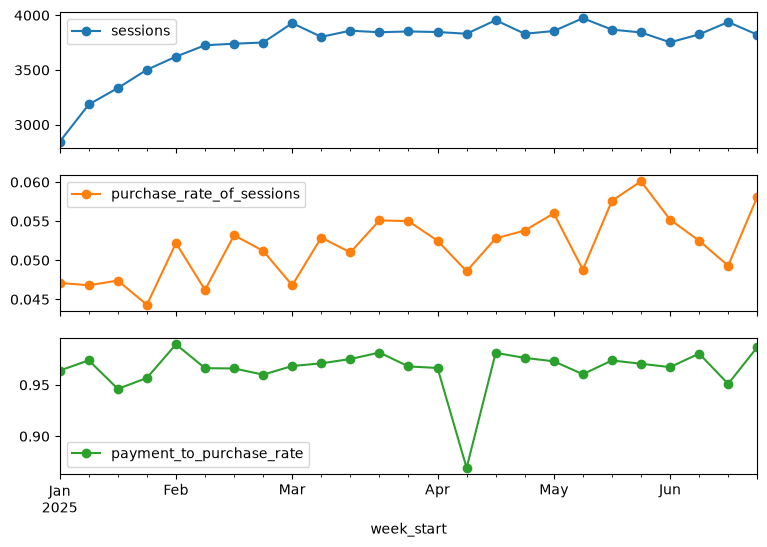

In [8]:
wk = m.weekly_trend(sf); wk[wk.days_in_data == 7].set_index('week_start')[['sessions','purchase_rate_of_sessions','payment_to_purchase_rate']].round(4).plot(subplots=True, figsize=(9, 6), marker='o'); plt.show()

In [9]:
print(m.payment_method_failures(d['events']).round(4)); print(m.retry_recovery(sf, d['events']))

  payment_method  attempts  failed_attempts  attempt_failure_rate
0            upi      2184              184                0.0842
1           card      1263              177                0.1401
2            cod      1142               13                0.0114
3     netbanking       425               53                0.1247
4         wallet       397               17                0.0428


{'sessions_with_attempt': 5128, 'sessions_with_failure': 417, 'recovered': 244, 'recovery_rate': 0.5851318944844125}


In [10]:
m.checkout_friction(sf, d['events']).round(4)

,checkout_type,shipping,checkout_sessions,payment_attempts,purchases,checkout_to_payment_rate,checkout_to_purchase_rate
0,account,fee_charged,898,675,647,0.7517,0.7205
1,account,free_shipping,3165,2511,2437,0.7934,0.7700
2,guest,fee_charged,654,429,414,0.6560,0.6330
3,guest,free_shipping,2291,1513,1457,0.6604,0.6360


**Caution:** this table conditions on sessions that already started checkout. Shipping fee is only recorded at `checkout_start`, so fee effects on cart→checkout cannot be observed directly (a limitation), and guest/fee groups differ in device and customer type.

## 5. Customer-level vs session-level, repeat purchase

In [11]:
print(m.customer_level(sf)); print(m.repeat_purchase(d['orders']))

{'customers': 60000, 'purchasing_customers': 4736, 'customer_conversion_rate': 0.07893333333333333, 'first_session_conversion_rate': 0.04003333333333333, 'avg_sessions_per_customer': 1.59385, 'session_conversion_rate': 0.051813742405705264}
{'customers_with_order': 4748, 'repeat_customers': 209, 'repeat_purchase_rate': 0.04401853411962932, 'total_orders': 4967, 'avg_days_between_1st_and_2nd_order': 16.700460969342547}


Repeat purchase is a lower bound: customers first seen late in the window have little time to buy again (right-censoring).